# 📊 Data Preprocessing: Discretization (Binning)

## 1. What is Discretization?
**Discretization** is the process of transforming continuous variables into discrete variables by creating a set of contiguous intervals that span the range of the variable's values. 

It is also commonly referred to as **binning**, where *"bin"* serves as an alternative name for an interval.

---

## 2. Why Use Discretization?

1. **To Handle Outliers:** By grouping extreme values into an open-ended edge bin (e.g., `> 80`), outliers lose their disproportionate mathematical leverage over linear algorithms.
2. **To Improve the Value Spread:** It simplifies non-linear distributions into manageable categorical fragments, exposing patterns that might be masked by noisy continuous spacing.

---

## 3. Visual Concept
```text
  Continuous Density Profile                     Binned Intervals
       _.._                                        █      █
     .'    `.                                      █  █   █
    /        \      ───────────────>               █  █   █   █
  _/__________\_                                 |___|___|___|___|
                                                 0-10 10-20 ...
```

In [1]:
import pandas as pd
import numpy as np

In [6]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

In [7]:
df = pd.read_csv('train.csv', usecols=['Age', 'Fare', 'Survived'])

In [8]:
df.dropna(inplace=True)

In [9]:
df.shape

(714, 3)

In [10]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [11]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
X_train.head(2)

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542


In [17]:
clf = DecisionTreeClassifier()

In [18]:
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

In [19]:
accuracy_score(y_test, y_pred)

0.6433566433566433

In [20]:
np.mean(cross_val_score(DecisionTreeClassifier(), X,y, cv=10, scoring='accuracy'))

np.float64(0.624706572769953)

In [63]:
kbin_age = KBinsDiscretizer(n_bins=15, encode='ordinal', strategy='quantile')
kbin_fare = KBinsDiscretizer(n_bins=15, encode='ordinal', strategy='quantile')

In [64]:
trf = ColumnTransformer([
    ('first', kbin_age, [0]),
    ('second', kbin_fare, [1])
])

In [65]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [66]:
trf.named_transformers_['first'].n_bins_

array([15])

In [67]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42,  6.  , 16.  , 19.  , 21.  , 23.  , 25.  , 28.  , 30.  ,
              32.  , 35.  , 38.  , 42.  , 47.  , 54.  , 80.  ])             ],
      dtype=object)

In [68]:
output = pd.DataFrame({
    'age':X_train['Age'],
    'age_trf':X_train_trf[:,0],
    'fare':X_train['Fare'],
    'fare_trf':X_train_trf[:,1]
})

In [69]:
output['age_labels'] = pd.cut(x=X_train['Age'],
                              bins=trf.named_transformers_['first'].bin_edges_[0].tolist())
output['fare_labels'] = pd.cut(x=X_train['Fare'],
                               bins=trf.named_transformers_['second'].bin_edges_[0].tolist())

In [70]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
387,36.0,10.0,13.0000,6.0,"(35.0, 38.0]","(10.5, 13.0]"
514,24.0,5.0,7.4958,1.0,"(23.0, 25.0]","(7.25, 7.775]"
94,59.0,14.0,7.2500,1.0,"(54.0, 80.0]","(0.0, 7.25]"
432,42.0,12.0,26.0000,9.0,"(38.0, 42.0]","(18.75, 26.0]"
642,2.0,0.0,27.9000,10.0,"(0.42, 6.0]","(26.55, 31.275]"


In [71]:
clf = DecisionTreeClassifier()

In [72]:
clf.fit(X_train_trf, y_train)
y_pred2 = clf.predict(X_test_trf)

In [73]:
accuracy_score(y_test, y_pred2)

0.6363636363636364

In [74]:
X_trf = trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(), X, y, cv=10, scoring='accuracy'))

np.float64(0.6317097026604068)

In [83]:
def discretize(bins, strategy):
    # 1. Initialize discretizers with matching spelling
    kbin_age = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)

    # 2. Bundle into a ColumnTransformer
    trf = ColumnTransformer([
        ('first', kbin_age, [0]),   # Assumes Age is the 1st column
        ('second', kbin_fare, [1])  # Assumes Fare is the 2nd column
    ])

    # 3. Transform the feature matrix
    X_trf = trf.fit_transform(X)
    
    # FIX: Pass X_trf (the discretized data) instead of raw X to evaluate properly
    # FIX: Fixed spelling of DecisionTreeClassifier
    accuracy = np.mean(cross_val_score(DecisionTreeClassifier(), X_trf, y, cv=10, scoring='accuracy'))
    print(f"Strategy: {strategy} | Bins: {bins} | Accuracy: {accuracy:.4f}")

    # 4. Plot distributions
    plt.figure(figsize=(14, 4))
    
    plt.subplot(121)
    plt.hist(X.iloc[:, 0]) # Safe column selection matching your transformer index
    plt.title("Before (Age)")
    
    plt.subplot(122)
    plt.hist(X_trf[:, 0], color='red')
    plt.title(f"After Discretization ({strategy.capitalize()})")
    
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(14, 4))

    plt.subplot(121)
    plt.hist(X.iloc[:, 1])  # Column selection for Fare matching your transformer index
    plt.title("Before (Fare)")
    
    plt.subplot(122)
    plt.hist(X_trf[:, 1], color='red')
    plt.title(f"After Discretization ({strategy.capitalize()})")
    
    plt.tight_layout()
    plt.show()

Strategy: uniform | Bins: 10 | Accuracy: 0.6865


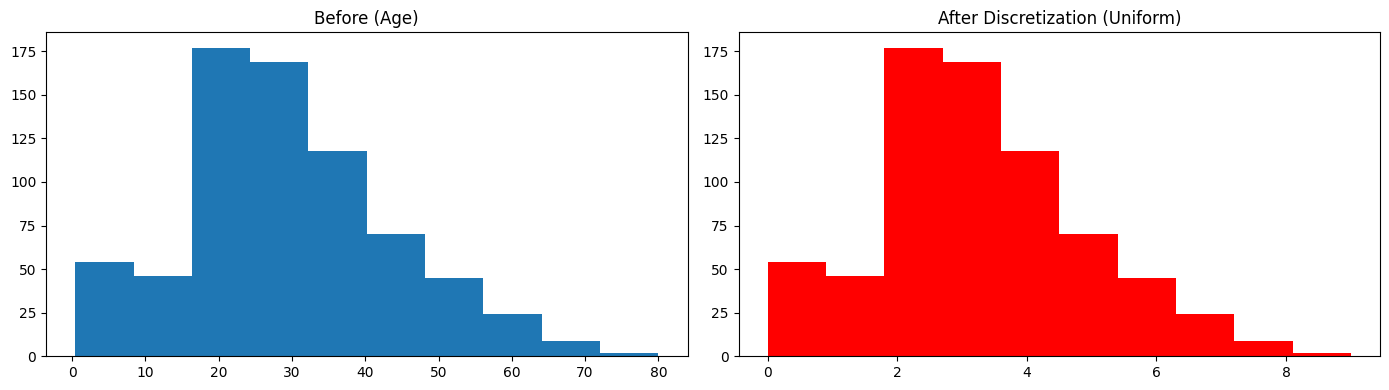

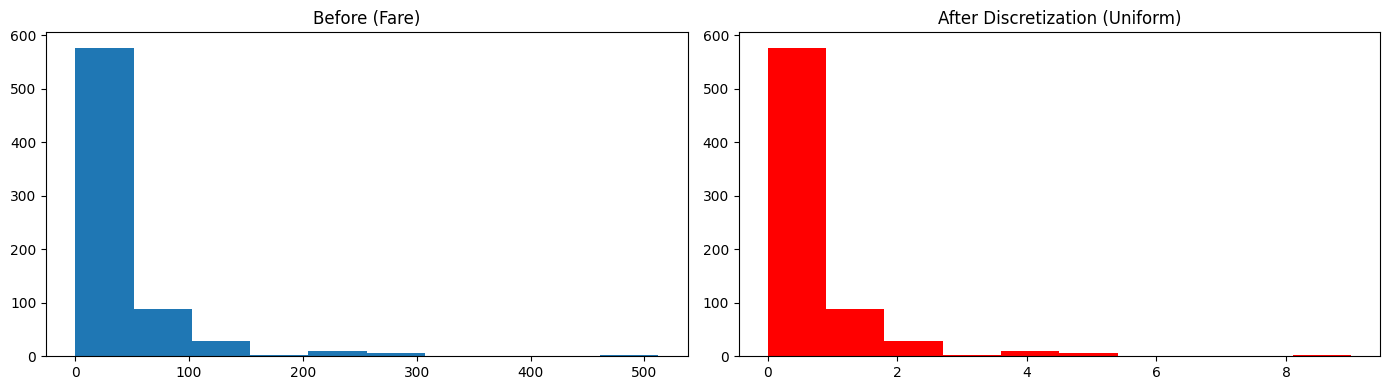

In [85]:
discretize(10, 'uniform')

## Binarization

In [86]:
df = pd.read_csv('train.csv')[['Age', 'Fare', 'SibSp', 'Parch', 'Survived']]

In [87]:
df.dropna(inplace=True)

In [88]:
df.head()

,Age,Fare,SibSp,Parch,Survived
0,22.0,7.2500,1,0,0
1,38.0,71.2833,1,0,1
2,26.0,7.9250,0,0,1
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,0


In [89]:
df['Family'] = df['SibSp'] + df['Parch']

In [90]:
df

,Age,Fare,SibSp,Parch,Survived,Family
0,22.0,7.2500,1,0,0,1
1,38.0,71.2833,1,0,1,1
2,26.0,7.9250,0,0,1,0
3,35.0,53.1000,1,0,1,1
4,35.0,8.0500,0,0,0,0
...,...,...,...,...,...,...
885,39.0,29.1250,0,5,0,5
886,27.0,13.0000,0,0,0,0
887,19.0,30.0000,0,0,1,0
889,26.0,30.0000,0,0,1,0


In [91]:
df.drop(columns=['SibSp', 'Parch'], inplace=True)

In [93]:
df.head()

,Age,Fare,Survived,Family
0,22.0,7.2500,0,1
1,38.0,71.2833,1,1
2,26.0,7.9250,1,0
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [94]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [95]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [96]:
X_train.head()

,Age,Fare,Family
328,31.0,20.5250,2
73,26.0,14.4542,1
253,30.0,16.1000,1
719,33.0,7.7750,0
666,25.0,13.0000,0


In [98]:
clf = DecisionTreeClassifier()

In [99]:
# Without Binarization
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

accuracy_score(y_test, y_pred)

0.6363636363636364

In [100]:
np.mean(cross_val_score(DecisionTreeClassifier(), X, y, cv=10, scoring='accuracy'))

np.float64(0.6499021909233177)

In [101]:
# Applying Binarization

from sklearn.preprocessing import Binarizer

In [104]:
trf = ColumnTransformer([
    ('bin', Binarizer(copy=False), ['Family'])
], remainder='passthrough')

In [105]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [107]:
pd.DataFrame(X_train_trf, columns=['Family', 'Age', 'Fare'])

,Family,Age,Fare
0,1.0,31.0,20.5250
1,1.0,26.0,14.4542
2,1.0,30.0,16.1000
3,0.0,33.0,7.7750
4,0.0,25.0,13.0000
...,...,...,...
566,1.0,46.0,61.1750
567,0.0,25.0,13.0000
568,0.0,41.0,134.5000
569,1.0,33.0,20.5250


In [108]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf, y_train)
y_pred2 = clf.predict(X_test_trf)

accuracy_score(y_test, y_pred2)

0.6083916083916084

In [109]:
X_trf = trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(), X_trf, y, cv=10, scoring='accuracy'))

np.float64(0.6219679186228481)